# AIOps 02 — Anomalias e triagem de VMs com métricas observadas
**RMC AI Labs | Continuação do laboratório PCA + K-Means + t-SNE.**

Este notebook usa registros históricos observados (identificadores pseudonimizados). Não usa dados sintéticos. Uma anomalia estatística não é diagnóstico nem justificativa automática para alterar recursos.

**Pré-requisito:** copiar os CSVs pseudonimizados para `data/pseudonimizados/` no clone local. **Não subir dados operacionais ao GitHub sem autorização.**

## 1. Leitura e auditoria
Os campos `date` originais são números de série de data da planilha; os percentuais são mantidos sem alteração. A etapa de leitura não exibe nomes reais nem identificadores da fonte.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

root=Path.cwd()
if root.name=='notebooks': root=root.parent
base_dir=root/'data'/'pseudonimizados'
if not base_dir.exists():
    raise FileNotFoundError(f'Copie o pacote pseudonimizado para: {base_dir}')
inv=pd.read_csv(base_dir/'vms_inventario.csv')
cpu=pd.read_csv(base_dir/'hist_cpu.csv')
mem=pd.read_csv(base_dir/'hist_mem.csv')
disk=pd.read_csv(base_dir/'hist_disk.csv')
print('VMs',len(inv),'CPU',len(cpu),'Memória',len(mem),'Disco',len(disk))
assert inv.vm.is_unique
assert set(cpu.vm).issubset(set(inv.vm))
assert set(mem.vm).issubset(set(inv.vm))

VMs 253 CPU 21199 Memória 21199 Disco 152509


## 2. Engenharia de atributos
Agregamos CPU e memória por VM (média, máximo, desvio-padrão). Para disco, o maior uso percentual entre volumes e dias. Isso identifica candidatos à investigação, mas não substitui o contexto operacional. `max` não deve ser confundido com percentil 95.

In [2]:
def agregados(df,p):
    return df.groupby('vm').used_pct.agg(['mean','max','std','count']).rename(columns={v:f'{p}_{v}' for v in ['mean','max','std','count']})
quadro=inv.merge(agregados(cpu,'cpu'),on='vm',how='left').merge(agregados(mem,'mem'),on='vm',how='left')
quadro=quadro.merge(disk.groupby('vm').used_pct.agg(disk_max='max').reset_index(),on='vm',how='left')
atributos=['cpu_mean','cpu_max','cpu_std','mem_mean','mem_max','mem_std','disk_max']
validos=quadro[atributos].notna().all(axis=1)
base=quadro.loc[validos].copy()
print('VMs com todos os atributos:',len(base),' / ',len(quadro))
print('Ausências por atributo:',quadro[atributos].isna().sum().to_dict())

VMs com todos os atributos: 221  /  253
Ausências por atributo: {'cpu_mean': 12, 'cpu_max': 12, 'cpu_std': 13, 'mem_mean': 12, 'mem_max': 12, 'mem_std': 13, 'disk_max': 29}


## 3. Isolation Forest
Usamos RobustScaler para preservar comparabilidade das escalas e `contamination=0.05` como **parâmetro experimental**, não como prevalência conhecida de incidentes. A amostra inclui apenas VMs com todos os atributos.

In [3]:
X=RobustScaler().fit_transform(base[atributos])
modelo=IsolationForest(n_estimators=250,contamination=0.05,random_state=42)
base['anomalia']=modelo.fit_predict(X)==-1
base['score_anomalia']=-modelo.score_samples(X)
print('VMs consideradas anômalas:',int(base.anomalia.sum()))

VMs consideradas anômalas: 11


## 4. Cruzamento independente com os alertas da coleta
Os arquivos `*_acima_th.csv` registram violações de limiares de origem; não aplicamos novos limites inventados. Sobreposição com Isolation Forest **não confirma** que o alerta é causa ou consequência da anomalia.

In [4]:
alertas={
 'cpu':pd.read_csv(base_dir/'cpu_acima_th.csv'),
 'mem':pd.read_csv(base_dir/'mem_acima_th.csv'),
 'disk':pd.read_csv(base_dir/'disk_vms_acima_th.csv')}
for tipo,dados in alertas.items():
    base[f'{tipo}_limiar_observado']=base.vm.isin(dados.vm)
base['limiar_qualquer']=base[[f'{tipo}_limiar_observado' for tipo in alertas]].any(axis=1)
base['classe_triagem']=np.select([base.anomalia & base.limiar_qualquer,base.limiar_qualquer,base.anomalia],['Anomalia + limiar','Limiar observado','Anomalia estatística'],default='Monitoramento')
print(base.classe_triagem.value_counts())
print('VMs com anomalia e limiar:',int((base.anomalia & base.limiar_qualquer).sum()))

classe_triagem
Monitoramento           152
Limiar observado         58
Anomalia estatística      7
Anomalia + limiar         4
Name: count, dtype: int64
VMs com anomalia e limiar: 4


## 5. Visualização e limites de interpretação
O gráfico mostra atributos agregados, não a causa de um incidente. Pontos próximos podem ter séries temporais e criticidades diferentes.

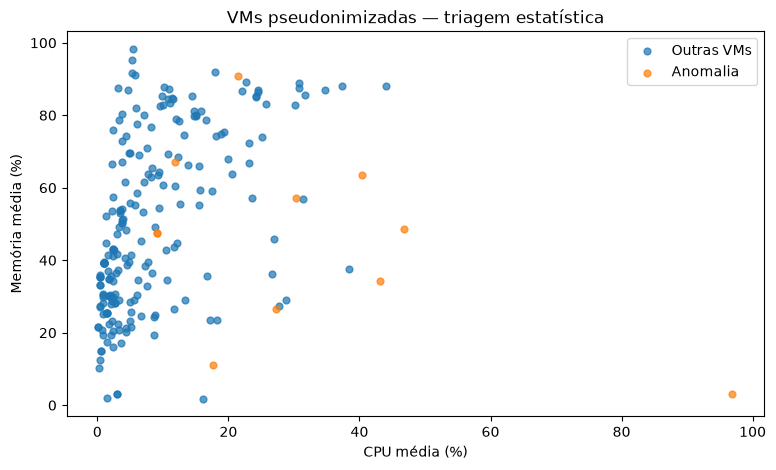

In [5]:
fig,ax=plt.subplots(figsize=(9,5))
for rot,subset in base.groupby('anomalia'):
    ax.scatter(subset.cpu_mean,subset.mem_mean,label='Anomalia' if rot else 'Outras VMs',alpha=.72,s=24)
ax.set(xlabel='CPU média (%)',ylabel='Memória média (%)',title='VMs pseudonimizadas — triagem estatística')
ax.legend();plt.show()

## 6. Tabela para investigação humana
Identificadores pseudonimizados são suficientes para o laboratório. Não inclui hostnames, UUIDs, IPs ou outros nomes originais. Nenhum resultado automatizado autoriza alterações em infraestrutura.

In [6]:
campos=['vm','cpu_mean','mem_mean','disk_max','score_anomalia','anomalia','limiar_qualquer','classe_triagem']
print(base[campos].sort_values('score_anomalia',ascending=False).head(12).to_string(index=False))
print('Total inventário:',len(inv))
print('Total válido:',len(base))

               vm  cpu_mean  mem_mean  disk_max  score_anomalia  anomalia  limiar_qualquer       classe_triagem
 VM-PACIFICO-0037 96.916462  3.018587 98.761506        0.758277      True             True    Anomalia + limiar
 VM-PACIFICO-0036 21.528692 90.719614 90.327354        0.643842      True             True    Anomalia + limiar
   VM-ARTICO-0192 46.815946 48.594508 79.575568        0.619710      True            False Anomalia estatística
   VM-INDICO-0133 43.067918 34.138811 81.595248        0.619582      True             True    Anomalia + limiar
VM-ATLANTICO-0094 17.693023 11.048591 59.973730        0.596131      True            False Anomalia estatística
  VM-AUSTRAL-0250  9.171899 47.628707 78.752558        0.582857      True            False Anomalia estatística
VM-ATLANTICO-0113 11.921478 67.137241 93.049285        0.580508      True             True    Anomalia + limiar
 VM-PACIFICO-0039 40.416651 63.485673 76.242580        0.579356      True            False Anomalia esta

## 7. Exercícios
1. Por que apenas as VMs com todos os atributos são analisadas?
2. Por que `contamination=0.05` não significa que 5% dos servidores estão com incidentes?
3. Compare uma VM anômala sem alertas e uma com alertas sem anomalia.
4. Qual diferença entre máximo de CPU, p95 e média?
5. Como o perfil de PCA + K-Means do post anterior complementaria a triagem?

**Limites:** O dataset é pseudonimizado, mas ainda contém dados operacionais; obtenha autorização antes de torná-lo público. Não estimamos causa raiz, economia nem impacto em produção.